<div align="center">

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/fabianalexisbernabecruz-code/portafolio-actuaria-unam/blob/main/04_Data_Structures_Trees_Dicts.ipynb)
[![GitHub](https://img.shields.io/badge/GitHub-Repository-181717?logo=github)](https://github.com/fabianalexisbernabecruz-code/portafolio-actuaria-unam)

</div>



<font face="Times New Roman">

 <img src="https://upload.wikimedia.org/wikipedia/commons/c/ca/Escudo-UNAM-escalable.svg" width="150" height="170" align="left"/>

  <img src="https://upload.wikimedia.org/wikipedia/commons/5/5b/Escudo-facultad-ciencias-unam-escalable.svg" width="150" height="170" align="right"/>

<h5 align="center"><i> </i></h5>
<h1 align="center"><b>Estructuras de Datos Avanzadas</b></h1>
</font>
<font face="Times New Roman">

---
---

<h2 align="center"><i>Árboles Binarios de Búsqueda y Diccionarios</i></h2>
<h5 align="center"><i>Implementación de árboles BST y diccionarios con análisis de complejidad espacial y temporal.</i></h5>

---
---

<h5 align="center"><i>Universidad Nacional Autónoma de México</i></h5>
<h5 align="center"><i>Facultad de Ciencias — Actuaría</i></h5>
<h5 align="center"><i>Materia: Manejo de Datos</i></h5>

---
---

<font color="Black" face="Times New Roman">
<h5 align="center"><i>Bernabe Cruz Fabian Alexis</i></h5>

</font>
</font>

<font color="Teal" face="Times New Roman">
  <h1 align="center" style="font-size: 24px;"><b>Proyecto — Árboles y Diccionarios</b></h1>
</font>

<font color="Black" face="Times New Roman">
  <h5 align="center"><i>Autor: Bernabe Cruz Fabian Alexis</i></h5>
</font>


<font face="Times New Roman">

## Esta sección es solo para copiar y pegar las clases necesarias para crear los arboles

</font>

In [ ]:
# Clase Nodo necesaria para generar arboles binarios
class Nodo(object):
  '''
  Constructor de nodos
  dato: es el contenido del nodo
  '''
  def __init__(self, dato):
    self.izq = None
    self.dato = dato
    self.der = None
    self.padre = None

  # Nos dice si el nodo tiene al menos un hijo
  def tieneHijos(self):
    return self.izq is not None and self.der is not None

  # Nos dide si el nodo es un hijo izquierdo
  def esIzq(self):
    return self.padre.izq == self

  # Nos dice si el nodo es un hijo derecho
  def esDer(self):
    return self.padre.der == self

  # Imprime el contenido del nodo
  def __str__(self):
    if self.dato is None:
      pass
    else:
      return '{}'.format(self.dato)


In [ ]:
import random

''' Clase AB (ArbolBinario), genera la estructura de un arbol binario, asi como sus funciones.'''
class AB(object):

  ''' Consructor de arboles binarios'''
  def __init__(self, dato):
    self.raiz = Nodo(dato)

  ''' Elimina todo el arbol'''
  def elimina(self):
    self.raiz = None

  ''' Devuelve el nivel del nodo que se le pasa como parametro.
      La raiz se ubica en el nivel cero'''
  def nivel(self, nodo):
    if nodo is None:
      return -1
    else:
      return 1 + self.nivel(nodo.padre)

  ''' Devuelve la altura a partir del nodo que se le pasa como parametro,
      si el arbol es vacio la altura es cero, si no se le suma 1 al maximo
      de las alturas de sus hijos'''
  def altura(self, nodo):
    if nodo is None:
      return 0
    else:
      return 1 + max(self.altura(nodo.izq), self.altura(nodo.der))

  ''' Inserta recursivamente un dato en el arbol de manera recursiva
      nodo: es el nodo a partir del cual se quiere insertar
      dato: es el dato que se quiere insertar
  '''
  def insertar_nodo(self, nodo, dato):
    # si el nodo es vacio ahi se crea el nuevo nodo
    if nodo is None:
      nuevo_nodo = Nodo(dato)
      return nuevo_nodo
    # dado que en los AB no hay un orden el nuevo nodo se inserta donde sea
    if bool(random.getrandbits(1)):
      nuevo_nodo = self.insertar_nodo(nodo.izq, dato)
      nodo.izq = nuevo_nodo
      nuevo_nodo.padre = nodo
    else:
      nuevo_nodo = self.insertar_nodo(nodo.der, dato)
      nodo.der = nuevo_nodo
      nuevo_nodo.padre = nodo
    #nodo guarda toda la ruta de donde sera insertado el dato
    #hasta caer en el caso base, es por eso que se devuelve
    return nodo

  ''' Inserta un nodo en el arbol, a partir de la raiz'''
  def insertar(self, dato):
    #Se inserta el dato desde la raiz
    self.insertar_nodo(self.raiz, dato)

  ''' Recorre el arbol enorden e imprime cada uno de sus nodos'''
  def recorrido_enorden(self, nodo):
    if nodo is not None:
      self.recorrido_enorden(nodo.izq)
      print(nodo.dato)
      self.recorrido_enorden(nodo.der)

  ''' Recorre el arbol preorden e imprime cada uno de sus nodos'''
  def recorrido_preorden(self, nodo):
    if nodo is not None:
      print(nodo.dato)
      self.recorrido_preorden(nodo.izq)
      self.recorrido_preorden(nodo.der)

  ''' Recorre el arbol postorden e imprime cada uno de sus nodos'''
  def recorrido_postorden(self, nodo):
    if nodo is not None:
      self.recorrido_postorden(nodo.izq)
      self.recorrido_postorden(nodo.der)
      print(nodo.dato)

In [ ]:

''' Clase arbol binario de busqueda, genera la estructura de un arbol binario
    de busqueda asi como sus funciones.'''
class ABB(AB):
  ''' Consructor de arboles'''
  def __init__(self, dato):
    # llamamos al constructor de la clase padre con la palabra super
    super(ABB, self).__init__(dato)
    # y se agrega la variable ultimo agregado que sirve para clases posteriores
    self.ultimo_agregado = self.raiz

  ''' Busca un dato en el arbol y devuelve el nodo'''
  def busqueda(self, nodo, dato):
    # si la raiz es None o el dato esta contenido en el nodo,
    # se devuelve el nodo.
    if nodo is None or nodo.dato == dato:
      return nodo
    # si el dato es mayo entonces se busca del lado derecho
    if nodo.dato < dato:
      return self.busqueda(nodo.der, dato)
    # si no, se busca en el lado izquierdo
    else:
      return self.busqueda(nodo.izq, dato)

  ''' Inserta un elemento en el arbol a partir de un nodo'''
  def insertar_nodo(self, nodo, dato):
    # si el nodo es vacio ahi se crea el nuevo nodo
    if nodo is None:
      nuevo_nodo = Nodo(dato)
      self.ultimo_agregado = nuevo_nodo
      return nuevo_nodo
    # si el dato es menor que su padre, se inserta en el lado izquierdo
    if dato < nodo.dato:
      nuevo_nodo = self.insertar_nodo(nodo.izq, dato)
      nodo.izq = nuevo_nodo
      nuevo_nodo.padre = nodo
    # de no ser asi se inserta del lado derecho
    else:
      nuevo_nodo = self.insertar_nodo(nodo.der, dato)
      nodo.der = nuevo_nodo
      nuevo_nodo.padre = nodo
    # nodo guarda toda la ruta de donde sera insertado el dato
    # hasta caer en el caso base, es por eso que se devuelve
    return nodo

  ''' Inserta un nodo en el arbol, a partir de la raiz'''
  def insertar(self, dato):
    # si el dato a insertar no se encuentra en el ABB se inserta
    if self.busqueda(self.raiz, dato) is None:
      # Se inserta el dato desde la raiz
      self.insertar_nodo(self.raiz, dato)

  ''' Busca el minimo en el subarbol a partir de nodo, este metodo sirve
      para poder eliminar nodos del arbol y mantener el orden'''
  def minimo_en_subarbol(self, nodo):
    # caso base en el que no hay minimo
    if nodo is None:
      return nodo
    # caso base en el que el nodo es el minimo ya que no tiene hijo izq
    if nodo.izq is None:
      return nodo
    # llamada recursiva para movernos al siguiente minimo
    return self.minimo_en_subarbol(nodo.izq)

  ''' Borra un nodo en el arbol, busca al nodo que contiene a dato
      y en caso de existir lo borra, se pueden dar multiples casos'''
  def borra_nodo(self, nodo, dato):
    # Caso 0) revisamos si el arbol es vacio.
    if self.raiz is None:
      return None
    # buscamos el nodo a borrar
    nodo_a_borrar = self.busqueda(nodo, dato)
    aux = nodo_a_borrar

    # Caso 0.1) si el dato no se encontro en el arbol no se puede borrar
    if nodo_a_borrar is None:
      return None

    # Caso 1) si el nodo a borrar es la RAIZ
    if nodo_a_borrar is self.raiz:
      # caso1.1) no tiene hijos, solo se borra la raiz
      if nodo_a_borrar.izq is None and nodo_a_borrar.der is None:
        self.raiz = None
        self.ultimo_agregado = None
        return None

      # Caso1.2) solo se tiene hijo derecho, entonces se sube al hijo derecho
      if nodo_a_borrar.izq is None and nodo_a_borrar.der is not None:
        self.raiz = nodo_a_borrar.der
        self.raiz.padre = None
        return self.raiz

      # Caso1.3) solo se tiene hijo izquierdo, entonces se sube al hijo izquierdo
      if nodo_a_borrar.izq is not None and nodo_a_borrar.der is None:
        self.raiz = nodo_a_borrar.izq
        self.raiz.padre = None
        return self.raiz

      # Caso1.4) tiene ambos hijos
      if nodo_a_borrar.izq is not None and nodo_a_borrar.der is not None:
        # buscamos el minimo en el subarbol derecho (minimo de los mayores)
        minimo = self.minimo_en_subarbol(nodo_a_borrar.der)
        aux = minimo.padre
        self.raiz.dato = minimo.dato
        self.borra_nodo(minimo, minimo.dato)
        return aux

    else: #Caso 2)
      # a partir de aqui se tienen 3 casos:
      # si no tiene hijos simplemente se borra el nodo
      # si tiene un solo hijo (ya sea izquierdo o derecho) se sube al unico hijo
      # tiene ambos hijos

      # es necesario identificar si el nodo a borrar es hijo izquierdo o derecho
      es_izquierdo = False
      if nodo_a_borrar.padre.izq == nodo_a_borrar:
        es_izquierdo = True

      # Caso2.1) no tiene hijos, solo se borra el nodo
      if nodo_a_borrar.izq is None and nodo_a_borrar.der is None:
        aux = nodo_a_borrar.padre
        # revisamos si el nodo a borrar es un hijo izquiero o derecho
        if es_izquierdo: # Caso2.1.1)
          aux.izq = None
        else: # Caso2.1.2)
          aux.der = None
        nodo_a_borrar = None
        return aux

      # Caso2.2) solo se tiene hijo izquierdo, entonces se sube al hijo izquierdo
      if nodo_a_borrar.izq is not None and nodo_a_borrar.der is None:
        nodo_a_borrar.izq.padre = nodo_a_borrar.padre
        aux = nodo_a_borrar.padre
        # revisamos si el nodo a borrar es un hijo izquiero o derecho
        if es_izquierdo: # Caso2.2.1)
          nodo_a_borrar.padre.izq = nodo_a_borrar.izq
        else: # Caso2.2.2)
          nodo_a_borrar.padre.der = nodo_a_borrar.izq
        return aux

      # Caso2.3) solo se tiene hijo derecho, entonces se sube al hijo derecho
      if nodo_a_borrar.izq is None and nodo_a_borrar.der is not None:
        nodo_a_borrar.der.padre = nodo_a_borrar.padre
        aux = nodo_a_borrar.padre
        # revisamos si el nodo a borrar es un hijo izquiero o derecho
        if es_izquierdo: # Caso2.3.1)
          nodo_a_borrar.padre.izq = nodo_a_borrar.der
        else: # Caso2.3.2)
          nodo_a_borrar.padre.der = nodo_a_borrar.der
        return aux

      # Caso2.4) tiene ambos hijos
      if nodo_a_borrar.izq is not None and nodo_a_borrar.der is not None:
        # buscamos el minimo en el subarbol derecho
        minimo = self.minimo_en_subarbol(nodo_a_borrar.der)
        aux = minimo.padre
        nodo_a_borrar.dato = minimo.dato
        self.borra_nodo(minimo, minimo.dato)
        return aux

  ''' Borra un nodo que contiene a dato a partir de la raiz'''
  def borrar(self, dato):
    self.borra_nodo(self.raiz, dato)

In [ ]:
class ArbolAVL(ABB):
  #Constructor que hace uso del constructor de la clase padre (ABB)
  def __init__(self, dato):
    super(ArbolAVL, self).__init__(dato)

  #Devuelve el ultimo nodo agregado para balanceo en caso necesario
  def ultimo(self):
    return self.ultimo_agregado

  #Determina si un nodo esta balanceado
  def balanceado(self, nodo):
    return abs(self.altura(nodo.der)-self.altura(nodo.izq)) <= 1

  '''
  2 = el subarbol esta muy cargado a la derecha
  1 = el subarbol esta cargado a la derecha
  0 = no hace falta rotar
  -1 = el subarbol esta cargado a la derecha
  -2 = el subarbol esta muy cargado a la izquierda
  '''
  def factor_equilibrio(self, nodo):
      if nodo is None:
          return 0
      else:
          return self.altura(nodo.der)-self.altura(nodo.izq)

  #Balancea el arbol, a partir de un nodo
  def balancea(self, nodo):
    #caso base
    if nodo is None:
      return
    if not self.balanceado(nodo):
      factorNodo = self.factor_equilibrio(nodo)
      factorIz = self.factor_equilibrio(nodo.izq)
      factorDer = self.factor_equilibrio(nodo.der)
      #Si el nodo esta desbalanceado se tendra uno de 4 casos
      #mismos que se solucionan con alguna de las 4 rotaciones
      if factorNodo == -2 and (factorIz == -1 or factorIz == 0): #probado
        self.rotacionSimpleDerecha(nodo)
      if factorNodo == 2 and (factorDer == 1 or factorDer == 0): #probado
        self.rotacionSimpleIzquierda(nodo)
      if factorNodo == -2 and factorIz == 1: #probado
        self.rotacionIzquierdaDerecha(nodo)
      if factorNodo == 2 and factorDer == -1: #probado
        self.rotacionDerechaIzquierda(nodo)
    #llamada recursiva para balancear toda la ruta. Desde donde se inserto
    #el nodo, hasta la raiz
    self.balancea(nodo.padre)

  #Rota el nodo a la derecha
  def rotacionSimpleDerecha(self, nodo):
    if nodo is not None:
      if nodo is self.raiz:
        #actualizamos la raiz
        self.raiz = nodo.izq
        self.raiz.padre = None
        # si el nodo.izq tiene hijo derecho se pasa como izq de nodo
        if nodo.izq.der is not None:
          nodo.izq.der.padre = nodo
          nodo.izq = nodo.izq.der
        else:
          nodo.izq = None
        self.raiz.der = nodo
        nodo.padre = self.raiz
      else:
        nuevaraiz = nodo.izq
        #actualizamos la nueva raiz
        if nodo.esIzq():
          nodo.padre.izq = nuevaraiz
        else:
          nodo.padre.der = nuevaraiz
        nuevaraiz.padre = nodo.padre
        # si el nodo.izq tiene hijo derecho se pasa como izq de nodo
        if nuevaraiz.der is not None:
          nuevaraiz.der.padre = nodo
          nodo.izq = nuevaraiz.der
        else:
          nodo.izq = None
        nuevaraiz.der = nodo
        nodo.padre = nuevaraiz

  #Rota el nodo a la izquierda
  def rotacionSimpleIzquierda(self, nodo):
    if nodo is not None:
      if nodo is self.raiz:
        #actualizamos la raiz
        self.raiz = nodo.der
        self.raiz.padre = None
        # si el nodo.der tiene hijo izquierdo se pasa como der de nodo
        if nodo.der.izq is not None:
          nodo.der.izq.padre = nodo
          nodo.der = nodo.der.izq
        else:
          nodo.der = None
        self.raiz.izq = nodo
        nodo.padre = self.raiz
      else:
        nuevaraiz = nodo.der
        #actualizamos la nueva raiz
        if nodo.esIzq():
          nodo.padre.izq = nuevaraiz
        else:
          nodo.padre.der = nuevaraiz
        nuevaraiz.padre = nodo.padre
        # si el nodo.der tiene hijo izquierdo se pasa como der de nodo
        if nuevaraiz.izq is not None:
          nuevaraiz.izq.padre = nodo
          nodo.der = nuevaraiz.izq
        else:
          nodo.der = None
        nuevaraiz.izq = nodo
        nodo.padre = nuevaraiz

  #Define la doble rotacion a la derecha, a partir de un nodo
  def rotacionIzquierdaDerecha(self, nodo):
    self.rotacionSimpleIzquierda(nodo.izq)
    self.rotacionSimpleDerecha(nodo)

  #Define la doble rotacion a la izquierda, a partir de un nodo
  def rotacionDerechaIzquierda(self, nodo):
    self.rotacionSimpleDerecha(nodo.der)
    self.rotacionSimpleIzquierda(nodo)

  #Inserta un nodo en el arbol y lo balancea, si es que se desbalanceo
  def insertar(self, dato):
    #Se inserta el dato usando el metodo de la clase padre
    super(ArbolAVL, self).insertar(dato)
    #Identificamos donde se inserto el dato
    ultimo_nodo_insertado = self.ultimo()

    #Se rebalancean los nodos que hayan quedado desbalanceados
    #Y se empieza desde el padre, por que nodo por def no pudo
    #haber quedado desbalanceado
    self.balancea(ultimo_nodo_insertado.padre)

  #Borra un nodo en el arbol y lo balancea, si es que se desbalanceo
  def borra(self, dato):
    #Se borra el nodo usando el metodo de la clase padre
    borradopadre = self.borra_nodo(self.raiz, dato)

    #Se rebalancean los nodos que hayan quedado desbalanceados
    #Y se empieza desde el padre, por que nodo por def, no pudo
    #haber quedado desbalanceado
    self.balancea(borradopadre)

<font face="Times New Roman">

# Arboles Binarios de Búsqueda

</font>

<font face="Times New Roman">

1. Genera un ABB, insertando los siguientes elementos [15, 10, 20, 8, 14, 0, 35, 99, 30] y muestra el resultado (una imágen).

</font>

In [ ]:
Arbol1 = ABB(15)
Arbol1.insertar(10)
Arbol1.insertar(20)
Arbol1.insertar(8)
Arbol1.insertar(14)
Arbol1.insertar(0)
Arbol1.insertar(35)
Arbol1.insertar(99)
Arbol1.insertar(30)

<font face="Times New Roman">

<center>
<img src= https://github.com/FabianABC0/Imagenes/blob/main/image.png?raw=true width="500">
</center>

</font>

<font face="Times New Roman">

2. Buscar el valor 14 (como no modifica la estructura, no es necesario mostrar el abb, pero si los pasos necesarios para buscar el valor 14), describe los pasos necesarios para localizar el valor 14 dentro del ABB.

</font>

<font face="Times New Roman">

1.   Se compara el valor 14 con la raíz que en este caso es 15, como 14 es menor a 15 entonces este se desplaza al hijo de la izquierda de la raíz.
  2.   Coomparamos el valor 14 con el hijo de la izquierda que en este caso es 10 y como 14 es mayor se desplzará hacia la derecha.
  3. Ahora 14 se comparará con el valor y al ser al mismo contenido en el nodo, se localizo al dato y el método devuelve el nodo que contiene a dicho valor.

</font>

<font face="Times New Roman">

3. Eliminar el valor 99.

</font>

In [ ]:
Arbol1.borrar(99)

<font face="Times New Roman">

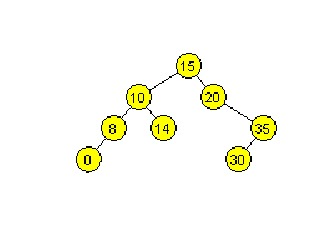

</font>

<font face="Times New Roman">

4. Eliminar el valor 15.

</font>

In [ ]:
Arbol1.borrar(15)

<font face="Times New Roman">

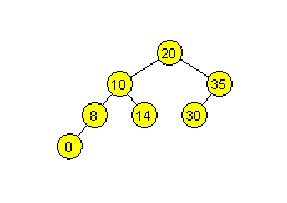

</font>

<font face="Times New Roman">

5. Insertar 90.

</font>

In [ ]:
Arbol1.insertar(90)

<font face="Times New Roman">

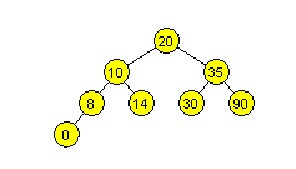

</font>

<font face="Times New Roman">

6. Después de haber realizado los puntos anteriores, muestra el resultado de recorrer el ABB en: Inorden, Preorden, Postorden.

</font>

<font face="Times New Roman">

INORDER: [0, 8, 10, 14, 15, 20, 30, 35, 99]

PREORDER [15, 10, 8, 0, 14, 20, 35, 30, 99]

POSTORDER [0, 8, 14, 10, 30, 99, 35, 20, 15]

</font>

<font face="Times New Roman">

7. Comprueba tus resultados usando la clase ABB y muestra los resultados en una celda de código.

</font>

In [ ]:
print("Recorrido en orden")
Arbol1.recorrido_enorden(Arbol1.raiz)

In [ ]:
print("Recorrido en preorden")
Arbol1.recorrido_preorden(Arbol1.raiz)

In [ ]:
print("Recorrido en postorden")
Arbol1.recorrido_postorden(Arbol1.raiz)

<font face="Times New Roman">

8. En una subsección llamada "Análisis", indica cuál es el peor caso para este tipo de árboles y explica a que orden de complejidad pertenecen las operaciones: eliminar árbol, buscar, insertar.

</font>

<font face="Times New Roman">

## ANALISIS

</font>

<font face="Times New Roman">

Peor caso

* El peor caso se produce cuando el elemento buscado es la hoja más profunda del árbol. La altura del árbol en el peor caso es igual a la cantidad de niveles en el árbol. Para un árbol binario de búsqueda con "n" elementos, la altura del árbol balanceado es log2(n), donde log2 representa el logaritmo en base 2. Entonces, en el peor caso, se necesitarán log2(n) comparaciones para encontrar un elemento que no esté presente en el árbol.

* Si el árbol binario de búsqueda no está balanceado y se convierte en un árbol degenerado (una lista enlazada), el peor caso se convierte en buscar un elemento que está en el extremo de la lista. En este caso, se requerirán "n" comparaciones para encontrar el elemento deseado.

</font>

<font face="Times New Roman">

* Eliminar (Delete):

En el peor caso, eliminar un nodo de un árbol binario de búsqueda puede ser una operación costosa si el árbol no está balanceado. En el peor caso, puede requerir recorrer todo el camino desde la raíz hasta el nodo a eliminar, lo que tiene un orden de complejidad de O(h), donde "h" es la altura del árbol en el peor caso.
En el mejor caso, cuando el nodo a eliminar es una hoja o un nodo con un solo hijo, la operación puede ser más eficiente, con un orden de complejidad de O(1).

* Buscar (Search):

En promedio, buscar un elemento en un árbol binario de búsqueda equilibrado tiene un orden de complejidad de O(log n), donde "n" es el número de nodos en el árbol. Esto se debe a que el árbol está equilibrado y se reduce a la mitad en cada paso.
En el peor caso, si el árbol no está equilibrado y se convierte en una lista enlazada, la búsqueda puede tener un orden de complejidad de O(n), donde "n" es el número de nodos en el árbol.

*Insertar (Insert):

Al igual que la búsqueda, en promedio, la inserción en un árbol binario de búsqueda equilibrado tiene un orden de complejidad de O(log n) debido a la necesidad de encontrar la ubicación adecuada para el nuevo elemento.
En el peor caso, cuando el árbol no está balanceado y se convierte en una lista enlazada, la inserción puede tener un orden de complejidad de O(n), donde "n" es el número de nodos en el árbol.

</font>

<font face="Times New Roman">

# Arboles Binarios Balanceados

</font>

<font face="Times New Roman">

1. Genera un ArbolAVL, insertando los siguientes elementos [15, 10, 5, 16, 17, 9, 20] y muestra el resultado (una imágen).

</font>

In [ ]:
# Vamos insertando elemento a elemento, el primero podemos tomarlo como raíz ya que realmente no importa cual se tome, y es en este
# nodo raíz en el que se comienza a crear el resto de nodos y hojas por eso hay una raíz inicial y el resto se usa el método insertar.
Arbol2 = ArbolAVL(15)
Arbol2.insertar(10)
Arbol2.insertar(5)
Arbol2.insertar(16)
Arbol2.insertar(17)
Arbol2.insertar(9)
Arbol2.insertar(20)

<font face="Times New Roman">

<center>
<img src= https://github.com/FabianABC0/Imagenes/blob/main/ArbolBalanceado.png?raw=true width="500">
</center>

</font>

<font face="Times New Roman">

2. Eliminar el valor 9, explica cada paso de manera detallada que se requiere para eliminar este valor.

</font>

In [ ]:
Arbol2.borra(9)

<font face="Times New Roman">

Primero se recibe el valor, en este caso $9$, se procede a comparar con la raíz, como no son iguales se pasa a el hijo izquierdo de la raíz ya que $9<10$ y es un $AAVL$, luego compara y como no son iguales se pasa al hijo derecho ya que $9>5$ y como esta hoja contiene el dato que queremos eliminar se elimina directamente, pero esto provoca que la raíz $10$ tenga un factor de equilibrio de 2 puesto que el hijo derecho tiene FE=1, lo que nos indica que se equilibrará con una rotación simple a la izquierda, esto hace que 16 pase a ser la raíz y 15 pase a ser el hijo derecho de 10, el resto sigue basicamente igual salvo sus FE.

</font>

<font face="Times New Roman">

3. Eliminar el valor 16, explica cada paso de manera detallada que se requiere para eliminar este valor.

</font>

In [ ]:
Arbol2.borra(16)

<font face="Times New Roman">

Primero se recibe el valor, luego se busca en la raíz 16 y como de hecho es el dato que queremos eliminar, entonces se procede a buscar al menor de los hijos derechos que es 17 y se coloca en lugar de la raíz y como esto no provoca un desbalanceo, finaliza la acción.

</font>

<font face="Times New Roman">

4. Insertar 1, explica cada paso de manera detallada que se requiere para insertar este valor.

</font>

In [ ]:
Arbol2.insertar(1)

<font face="Times New Roman">

Nuevamente, recibimos el dato, comparamos con la raíz, como $1<17$ pasamos al hijo izquierdo,comparamos con él y como $1<10$ pasamos al hijo izquierdo de este nuevamente, como $1<5$ nos vamos al hijo izquierdo de este y como no existe, este pasa a ser su hijo izquierdo. Lo anterior provoca un desbalance, la raíz tiene FE de -2, lo que se soluciona con una rotación simple a la derecha donde 15 pasa a ser hijo izquierdo de 17 y el arbol está equilibrado.

</font>

<font face="Times New Roman">

5. Después de haber realizado los puntos anteriores, muestra el resultado de recorrer el ABB en: Enorden, Preorden, Postorden.

</font>

In [ ]:
print("Recorrido en orden")
Arbol2.recorrido_enorden(Arbol2.raiz)


In [ ]:
print("Recorrido en preorden")
Arbol2.recorrido_preorden(Arbol2.raiz)


In [ ]:
print("Recorrido en postorden")
Arbol2.recorrido_postorden(Arbol2.raiz)

<font face="Times New Roman">

Mostramos el equilibrio del arbol

</font>

In [ ]:
print(Arbol2.factor_equilibrio(Arbol2.raiz))

<font face="Times New Roman">

6. En una subsección llamada "Análisis", indica cuál es el peor caso para este tipo de árboles y explica a que orden de complejidad pertenecen las operaciones: eliminar árbol, buscar, insertar.

</font>

<font face="Times New Roman">

El peor caso en un árbol AVL ocurre cuando las inserciones o eliminaciones provocan un desequilibrio en el árbol que al ser por definición balanceado se necesita realizar una serie de rotaciones para equilibrar el arbol de nuevo en terminos de que su $FE$ sea aceptable (1,-1,0). El peor caso específico se produce cuando estas operaciones provocan un camino largo y desequilibrado en el árbol, lo que puede llevar a una más operaciones en volver al equilibrio. Esto puede ocurrir cuando se insertan o eliminan nodos en orden ascendente o descendente.

Orden de complejidad:

En un comportamiento promedio está en el orden de complejidad de $log_{2}(n)$

+ Eliminar árbol (eliminar todos los nodos):
En el peor caso, eliminar un árbol AVL implica eliminar cada nodo uno por uno, lo que llevaría a una complejidad de $O(n)$, donde "n" es el número de nodos en el árbol.

* En caso de que el valor a buscar no exista en el árbol, aún así es necesario buscarlo en el mismo y en el mejor de los casos el máximo número de comparaciones realizadas sería logarítmica  $O(log2n)$  donde  n  es el número de nodos.
Buscar (búsqueda de un nodo específico):
En un árbol AVL equilibrado, la búsqueda tiene un orden de complejidad de  $O(log_{2}(n))$, ya que el árbol se divide en la mitad aproximadamente en cada paso de búsqueda (como busqueda binaria). Sin embargo, en el peor caso, cuando el árbol está completamente desequilibrado, la búsqueda puede requerir $O(n)$ operaciones, ya que se recorrerían todos los nodos.

* Insertar (inserción de un nuevo nodo):
 En un árbol AVL equilibrado, la inserción también tiene un orden de complejidad de $O(log n)$ en el peor caso, ya que se necesitan rotaciones para mantener el equilibrio del árbol. Sin embargo, si la inserción provoca un desequilibrio y se necesita una serie de rotaciones, el peor caso podría requerir $O(n)$ operaciones.

</font>

<font face="Times New Roman">

# Tablas Hash

</font>

<font face="Times New Roman">

1. Usando wget incluir en la sesión de jupyter el archivo llamado  [inteligencia.txt](https://raw.githubusercontent.com/jugernaut/ManejoDatos/desarrollo/utils/inteligencia.txt)

</font>

In [ ]:
!wget https://raw.githubusercontent.com/jugernaut/ManejoDatos/desarrollo/utils/inteligencia.txt

<font face="Times New Roman">

2. Generar un diccionario con la estructura {‘palabra1’:ocurrencia1, ‘palabra2’:ocurrencia2,..,’palabraN’:ocurrenciaN}. Dónde palabra (key) es alguna palabra y ocurrencia (value) es el número de veces que aparece esta palabra.

</font>

In [ ]:
# bibliotecas utilizadas
import re
import os
import urllib.request
from collections import Counter

# Implementación base para lectura y procesamiento de texto
def data_mining(ruta):
    # Resolución resiliente de ruta (directorio actual, carpeta data/ o descarga directa desde GitHub en Colab)
    if not os.path.exists(ruta):
        posibles_rutas = [
            os.path.join('data', ruta),
            os.path.join('..', 'data', ruta),
        ]
        for p in posibles_rutas:
            if os.path.exists(p):
                ruta = p
                break
        else:
            url = f'https://raw.githubusercontent.com/fabianalexisbernabecruz-code/portafolio-actuaria-unam/main/data/{os.path.basename(ruta)}'
            try:
                urllib.request.urlretrieve(url, ruta)
            except Exception:
                pass

    # Abrimos el archivo a leer con codificación segura
    with open(ruta, 'r', encoding='utf-8', errors='replace') as archivo:
        cadenota = archivo.read()

    # Generamos una lista con las palabras utilizando el espacio en blanco como delimitador
    lista_palabras = re.split(r'\s+', cadenota)

    # Diccionario para contar frecuencia de palabras
    diccionario = {}
    for palabra in lista_palabras:
        if palabra:
            diccionario[palabra] = diccionario.get(palabra, 0) + 1

    print('Total de palabras únicas:', len(diccionario))
    contador = Counter(diccionario)
    diccionarioOrdenado = contador.most_common()
    print('Top 15 palabras más comunes:', diccionarioOrdenado[:15])


<font face="Times New Roman">

3. Este diccionario debe contener todas las palabras del documento inteligencia.txt con su respectiva ocurrencia.

</font>

In [ ]:
data_mining("inteligencia.txt")

<font face="Times New Roman">

Una vez hecho esto sin considerar artículos preposiciones o pronombres, en una subsección llamada "De que trato el texto" debes indicar cuál fue la palabra que más se repite en el documento inteligencia.txt. El resultado debería verse similar a la siguiente imagen.

</font>

<font face="Times New Roman">

Considerando que la palabra que más se repite en el documento no debe ser artículos preposiciones o pronombres.

</font>

<font face="Times New Roman">

De qué trató el texto: Aprendizaje.
También de los modelos de Aprendizaje automático, algoritmos, inteligencia artificial, datos...

</font>

<font face="Times New Roman">

# Punto Extra

</font>

<font face="Times New Roman">

La herramienta trees.jar maneja muchos más tipos de árboles (no solo los que vimos en clase). En la parte superior de dicha herramienta pueden encontrar más pestañas con diferentes tipos de árboles. Revisa el resto de los árboles que maneja y en una sección llamada Arboles de la Barranca menciona las ventajas de cada uno y donde son empleados.

</font>

<font face="Times New Roman">

# ÁRBOLES DE LA BARRANCA

</font>

<font face="Times New Roman">

## B TREE

</font>

<font face="Times New Roman">

VENTAJAS:


* Los árboles B se equilibran por sí solos.
* Alta concurrencia y alto rendimiento.
* Los B-Trees tienen una complejidad temporal garantizada de O(log n) para operaciones básicas como inserción, eliminación y búsqueda, lo que los hace adecuados para grandes conjuntos de datos y aplicaciones en tiempo real.
* Utilización eficiente del almacenamiento.

APLICACIONES:

* Almacenar bloques de datos (medios de almacenamiento secundarios)
Se utiliza en grandes bases de datos para acceder a los datos almacenados en el disco.
* La búsqueda de datos en un conjunto de datos se puede lograr en mucho menos tiempo utilizando B-Tree.
* Con la función de indexación, se puede lograr una indexación multinivel.
* La mayoría de los servidores también utilizan el enfoque de árbol B.
* Los B-Trees se utilizan en sistemas CAD para organizar y buscar datos geométricos.
* Los B-Trees también se utilizan en otras áreas, como el procesamiento del lenguaje natural, las redes informáticas y la criptografía.

</font>

<font face="Times New Roman">

## AVL TREE

</font>

<font face="Times New Roman">

Ventajas:

* Los árboles AVL pueden autoequilibrarse.
* Seguramente no está sesgado.
* Proporciona búsquedas más rápidas que los árboles RED-BLACK.
* Mejor complejidad del tiempo de búsqueda en comparación con otros árboles como el árbol binario.
* La altura no puede exceder log(N), donde N es el número total de nodos en el árbol.

APLICACIONES:

* Se utiliza para indexar registros enormes en una base de datos y también para buscar de manera eficiente en ella.
* Para todo tipo de colecciones en memoria, incluidos conjuntos y diccionarios, se utilizan árboles AVL.
* Aplicaciones de bases de datos, donde las inserciones y eliminaciones son menos comunes pero son necesarias búsquedas frecuentes de datos.
* Software que necesita búsqueda optimizada.
* Se aplica en áreas corporativas y juegos argumentales.

</font>

<font face="Times New Roman">

## RED BLACK TREE

</font>

<font face="Times New Roman">

VENTAJAS:

* Los árboles RED- BLACK tienen una complejidad temporal garantizada de O (log n) para operaciones básicas como inserción, eliminación y búsqueda.
* Los árboles RED-BLACK se equilibran a sí mismos.
* Red Black Trees se puede utilizar en una amplia gama de aplicaciones debido a su rendimiento eficiente y versatilidad.
 * El mecanismo utilizado para mantener el equilibrio en Red Black Trees es relativamente simple y fácil de entender.

APLICACIONES:
* La mayoría de las funciones de la biblioteca BST con equilibrio automático, como map, multiset y multimap en C++ (o paquetes java como java.util.TreeMap y java.util.TreeSet) utilizan árboles RED-BLACK
* Se utiliza para implementar la programación de CPU de Linux. Completely Fair Scheduler lo usa.

* También se utiliza en el algoritmo de agrupamiento en clústeres K-mean en el aprendizaje automático para reducir la complejidad del tiempo.
Además, MySQL también utiliza el árbol Red-Black para índices en tablas para reducir el tiempo de búsqueda e inserción.
* Los árboles RED-BLACK se utilizan en la implementación del administrador de memoria virtual en algunos sistemas operativos, para realizar un seguimiento de las páginas de memoria y su uso.
* Muchos lenguajes de programación como Java, C++ y Python han implementado Red Black Trees como una estructura de datos incorporada para una búsqueda y clasificación de datos eficiente.
* Los árboles rojos y negros se utilizan en la implementación de algoritmos gráficos como el algoritmo de ruta más corta de Dijkstra y el algoritmo de árbol de expansión mínima de Prim.
* Los árboles rojos y negros se utilizan en la implementación de motores de juegos.

</font>

<font face="Times New Roman">

##  AA TREE

</font>

<font face="Times New Roman">

VENTAJAS:
* La implementación y el número de casos de rotación en Red-Black Trees es complejo. Los árboles AA simplifican el algoritmo.
* Elimina la mitad del proceso de reestructuración al eliminar la mitad de los casos de rotación, lo que es más fácil de codificar.
* Simplifica el proceso de eliminación al eliminar múltiples casos.

APLICACIONES:

Almacenar y recuperar datos ordenados de manera eficiente.

</font>

<font face="Times New Roman">

## SKIPLIST

</font>

<font face="Times New Roman">

VENTAJAS:

* La lista de omisiones es sólida y confiable.
* Para agregarle un nuevo nodo, se insertará extremadamente rápido.
* Fácil de implementar en comparación con la tabla hash y el árbol de búsqueda binario
* El número de nodos en la lista de omisión aumenta y la posibilidad del peor de los casos disminuye
* Requiere sólo tiempo Θ(logn) en el caso promedio para todas las operaciones.
* Encontrar un nodo en la lista es relativamente sencillo.

APLICACIONES:
* Implementación de diccionarios o conjuntos ordenados
* Búsqueda en grandes conjuntos de datos
* Implementación de algoritmos eficientes para la resolución de problemas en geometría computacional.
* Optimización del rendimiento en bases de datos y motores de búsqueda.
* Las listas de omisión son una estructura de datos probabilística, lo que significa que el rendimiento está determinado por un proceso aleatorio. Son muy similares a los árboles equilibrados, pero son más sencillos de implementar y pueden consumir más memoria.

</font>

<font face="Times New Roman">

## MAX HEAP

</font>

<font face="Times New Roman">

VENTAJAS:

* Mantenga eficientemente el valor máximo: un montón máximo permite el acceso en tiempo constante al elemento máximo en el montón, lo que lo hace útil en aplicaciones donde el elemento máximo debe encontrarse rápidamente.
* Operaciones de inserción y eliminación eficientes: las operaciones de inserción y eliminación en un montón máximo tienen una complejidad temporal de O (log n), lo que las hace eficientes para grandes colecciones de elementos.
* Colas de prioridad: se puede utilizar un montón máximo para implementar una cola de prioridad, lo cual es útil en muchas aplicaciones, como programación de trabajos, priorización de tareas y simulación basada en eventos.
* Clasificación: se puede utilizar un montón máximo para implementar heapsort, que es un algoritmo de clasificación eficiente que tiene una complejidad temporal en el peor de los casos de O (n log n).
* Eficiencia espacial: se puede implementar un montón máximo como una matriz, lo que requiere menos memoria en comparación con otras estructuras de datos, como un árbol de búsqueda binario o una lista vinculada.

APLICACIONES:

La estructura de datos Max Heap es útil para ordenar datos mediante la clasificación de montón.

</font>

<font face="Times New Roman">

## MIN HEAP

</font>

<font face="Times New Roman">

VENTJAS:

* Inserción y eliminación eficientes : el montón mínimo permite la inserción y eliminación rápida de elementos con una complejidad temporal de O (log n), donde n es el número de elementos en el montón.
Recuperación eficiente del elemento mínimo: el elemento mínimo en un montón mínimo siempre está en la raíz del montón, que se puede recuperar en un tiempo O (1).
* Eficiencia en espacio: Min Heap es una estructura de datos compacta que se puede implementar mediante una matriz o un árbol binario, lo que la hace eficiente en espacio.
* Clasificación: el montón mínimo se puede utilizar para implementar un algoritmo de clasificación eficiente, como el tipo de montón con una complejidad temporal de O (n log n).
* Cola de prioridad: el montón mínimo se puede utilizar para implementar una cola de prioridad, donde el elemento con la prioridad mínima se puede recuperar de manera eficiente en tiempo O (1).
* Versatilidad: Min Heap tiene varias aplicaciones en informática, incluidos algoritmos gráficos, compresión de datos y sistemas de bases de datos.


APLICACIONES:
* Clasificación de montón: el montón mínimo se utiliza como componente clave en el algoritmo de clasificación de montón, que es un algoritmo de clasificación eficiente con una complejidad temporal de O (nlogn).
* Cola de prioridad: se puede implementar una cola de prioridad utilizando una estructura de datos de montón mínimo donde el elemento con el valor mínimo siempre está en la raíz.
* Algoritmo de Dijkstra: en el algoritmo de Dijkstra, se utiliza un montón mínimo para almacenar los vértices del gráfico con la distancia mínima desde el vértice inicial. El vértice con la distancia mínima siempre está en la raíz del montón.
* Codificación Huffman: en la codificación Huffman, se utiliza un montón mínimo para implementar una cola de prioridad para crear un código de prefijo óptimo para un conjunto determinado de caracteres.
* Fusionar K matrices ordenadas: dadas K matrices ordenadas, podemos fusionarlas en una única matriz ordenada de manera eficiente utilizando una estructura de datos de montón mínimo.

</font>

<font face="Times New Roman">

## TREAP

</font>

<font face="Times New Roman">

* Treap se utiliza como un árbol binario autoequilibrado. Dado que Treap es un árbol de búsqueda binario aleatorio, es decir, a cada nodo de BST se le asigna una prioridad aleatoria, aportará más equilibrio al árbol.
* Treap se utiliza para resolver problemas de conectividad.
* Treap se puede utilizar para encontrar la suma, el máximo y el mínimo en un rango determinado similar a un árbol de segmentos o una tabla dispersa.
* Treap se puede utilizar para agregar/pintar en un rango determinado.

APLICACIONES:

Se utiliza para resolver problemas de conectividad, problemas de consulta de rango, y puede usarse como buenas alternativas para segmentar árboles/tablas dispersas y distribuir árboles en algunos de los escenarios, ya que también son relativamente más fáciles de codificar.

</font>

<font face="Times New Roman">

## SCAPEGOAT TREE

</font>

<font face="Times New Roman">

VENTAJAS:

El árbol del scapegoat es el primer árbol de búsqueda binaria que alcanza su complejidad sin almacenar información adicional en cada nodo. Esto ahorra grandes cantidades de espacio, lo que lo convierte en un atractivo árbol de búsqueda binaria equilibrado.

APLICACIONES:

Donde dominan las operaciones de inserción y búsqueda porque ahí es donde el árbol scapegoat es más eficiente.

</font>

<font face="Times New Roman">

## SPLAY TREE

</font>

<font face="Times New Roman">

APLICACIONES:

* Almacenamiento en caché : los árboles de distribución se pueden utilizar para implementar la gestión de la memoria caché, donde los elementos a los que se accede con más frecuencia se mueven a la parte superior del árbol para un acceso más rápido.
* Indexación de bases de datos : los árboles de distribución se pueden utilizar para indexar bases de datos para una búsqueda y recuperación de datos más rápida.
* Sistemas de archivos : los árboles de distribución se pueden utilizar para almacenar metadatos del sistema de archivos, como la tabla de asignación, la estructura de directorios y los atributos del archivo.
* Compresión de datos: los árboles de dispersión se pueden utilizar para comprimir datos identificando y codificando patrones repetidos.
Procesamiento de texto : los árboles de visualización se pueden utilizar en aplicaciones de procesamiento de texto, como los correctores ortográficos, donde las palabras se almacenan en un árbol de visualización para una búsqueda y recuperación rápidas.
* Algoritmos de gráficos: los árboles de dispersión se pueden utilizar para implementar algoritmos de gráficos, como encontrar la ruta más corta en un gráfico ponderado.
* Juegos en línea: los árboles de distribución se pueden utilizar en juegos en línea para almacenar y administrar puntuaciones altas, tablas de clasificación y estadísticas de jugadores.

VENTAJAS:

Los árboles de distribución tienen una complejidad temporal amortizada de O (log n) para muchas operaciones, lo que los hace más rápidos que muchas otras estructuras de datos de árbol equilibrado en algunos casos.
Los árboles de expansión se ajustan automáticamente, lo que significa que se equilibran automáticamente a medida que se insertan y retiran elementos. Esto puede ayudar a evitar la degradación del rendimiento que puede ocurrir cuando un árbol se desequilibra.

</font>